In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
data = pd.read_csv("play_tennis_dataset.csv")
df = pd.DataFrame(data)
df

,Day,Outlook,Temperature,Humidity,Wind,Play
0,D1,Overcast,Mild,Normal,Strong,Yes
1,D2,Sunny,Mild,Normal,Strong,Yes
2,D3,NaN,Mild,High,Strong,No
3,D4,Sunny,Mild,High,Weak,Yes
4,D5,Sunny,Cool,Normal,Strong,Yes
...,...,...,...,...,...,...
6661,D28,Sunny,Mild,High,Weak,Yes
6662,D29,Rainy,Cool,High,Weak,No
6663,D30,Overcast,Cool,High,Weak,Yes
6664,D31,Sunny,Hot,High,Strong,No


In [3]:
df.head()

,Day,Outlook,Temperature,Humidity,Wind,Play
0,D1,Overcast,Mild,Normal,Strong,Yes
1,D2,Sunny,Mild,Normal,Strong,Yes
2,D3,NaN,Mild,High,Strong,No
3,D4,Sunny,Mild,High,Weak,Yes
4,D5,Sunny,Cool,Normal,Strong,Yes


In [4]:
df.tail()

,Day,Outlook,Temperature,Humidity,Wind,Play
6661,D28,Sunny,Mild,High,Weak,Yes
6662,D29,Rainy,Cool,High,Weak,No
6663,D30,Overcast,Cool,High,Weak,Yes
6664,D31,Sunny,Hot,High,Strong,No
6665,D1,Sunny,Cool,Normal,Strong,Yes


In [5]:
df.describe()

,Day,Outlook,Temperature,Humidity,Wind,Play
count,6666,6267,6333,6433,6300,6666
unique,31,3,3,2,2,2
top,D1,Overcast,Cool,Normal,Weak,Yes
freq,220,2192,2538,3872,4473,4080


In [6]:
df.columns

Index(['Day', 'Outlook', 'Temperature', 'Humidity', 'Wind', 'Play'], dtype='str')

In [7]:
df.shape

(6666, 6)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6666 entries, 0 to 6665
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Day          6666 non-null   str  
 1   Outlook      6267 non-null   str  
 2   Temperature  6333 non-null   str  
 3   Humidity     6433 non-null   str  
 4   Wind         6300 non-null   str  
 5   Play         6666 non-null   str  
dtypes: str(6)
memory usage: 471.6 KB


In [9]:
df.isna().sum()

Day              0
Outlook        399
Temperature    333
Humidity       233
Wind           366
Play             0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(4420)

In [11]:
df = df.drop("Day",axis= 1)
df

,Outlook,Temperature,Humidity,Wind,Play
0,Overcast,Mild,Normal,Strong,Yes
1,Sunny,Mild,Normal,Strong,Yes
2,NaN,Mild,High,Strong,No
3,Sunny,Mild,High,Weak,Yes
4,Sunny,Cool,Normal,Strong,Yes
...,...,...,...,...,...
6661,Sunny,Mild,High,Weak,Yes
6662,Rainy,Cool,High,Weak,No
6663,Overcast,Cool,High,Weak,Yes
6664,Sunny,Hot,High,Strong,No


In [12]:
df_1 = df["Play"].value_counts()

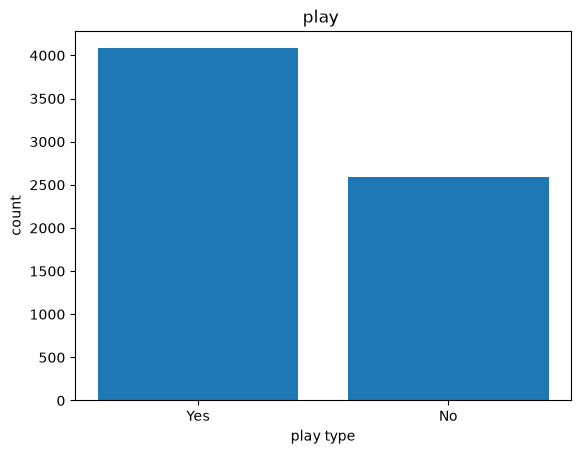

In [13]:

plt.bar(df_1.index,df_1.values)
plt.title("play ")
plt.xlabel("play type")
plt.ylabel("count")
plt.show()

In [14]:
X = df.drop("Play",axis = 1)

y = df["Play"]
X

,Outlook,Temperature,Humidity,Wind
0,Overcast,Mild,Normal,Strong
1,Sunny,Mild,Normal,Strong
2,NaN,Mild,High,Strong
3,Sunny,Mild,High,Weak
4,Sunny,Cool,Normal,Strong
...,...,...,...,...
6661,Sunny,Mild,High,Weak
6662,Rainy,Cool,High,Weak
6663,Overcast,Cool,High,Weak
6664,Sunny,Hot,High,Strong


In [15]:
X = pd.get_dummies(X)
X

,Outlook_Overcast,Outlook_Rainy,Outlook_Sunny,Temperature_Cool,Temperature_Hot,Temperature_Mild,Humidity_High,Humidity_Normal,Wind_Strong,Wind_Weak
0,True,False,False,False,False,True,False,True,True,False
1,False,False,True,False,False,True,False,True,True,False
2,False,False,False,False,False,True,True,False,True,False
3,False,False,True,False,False,True,True,False,False,True
4,False,False,True,True,False,False,False,True,True,False
...,...,...,...,...,...,...,...,...,...,...
6661,False,False,True,False,False,True,True,False,False,True
6662,False,True,False,True,False,False,True,False,False,True
6663,True,False,False,True,False,False,True,False,False,True
6664,False,False,True,False,True,False,True,False,True,False


In [16]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)


In [17]:
from sklearn.tree import DecisionTreeClassifier

model  = DecisionTreeClassifier(criterion="entropy")
model.fit(X_train,y_train)
y_pred = model.predict(X_test)
y_pred

array(['Yes', 'Yes', 'No', ..., 'No', 'No', 'Yes'],
      shape=(2000,), dtype=object)

In [18]:
from sklearn.metrics import accuracy_score

print(accuracy_score(y_test,y_pred))

0.8845


In [19]:
from sklearn.metrics import recall_score, confusion_matrix, classification_report

# Set pos_label='Yes' for binary string target
print("Recall (Play='Yes'):", recall_score(y_test, y_pred, pos_label='Yes'))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Recall (Play='Yes'): 0.9722222222222222

Confusion Matrix:
 [[ 579  197]
 [  34 1190]]

Classification Report:
               precision    recall  f1-score   support

          No       0.94      0.75      0.83       776
         Yes       0.86      0.97      0.91      1224

    accuracy                           0.88      2000
   macro avg       0.90      0.86      0.87      2000
weighted avg       0.89      0.88      0.88      2000

